<a href="https://colab.research.google.com/github/abhinayakscs25-svg/BIS/blob/main/1BM25CS403_lab_6_grey_wolf_optimization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Starting Grey Wolf Optimization...

Iteration 1/100 - Best Fitness: 0.02850
Iteration 2/100 - Best Fitness: 0.02633
Iteration 3/100 - Best Fitness: 0.01981
Iteration 4/100 - Best Fitness: 0.01981
Iteration 5/100 - Best Fitness: 0.01981
Iteration 6/100 - Best Fitness: 0.01981
Iteration 7/100 - Best Fitness: 0.01981
Iteration 8/100 - Best Fitness: 0.01981
Iteration 9/100 - Best Fitness: 0.01981
Iteration 10/100 - Best Fitness: 0.01976
Iteration 11/100 - Best Fitness: 0.01976
Iteration 12/100 - Best Fitness: 0.01976
Iteration 13/100 - Best Fitness: 0.01976
Iteration 14/100 - Best Fitness: 0.01976
Iteration 15/100 - Best Fitness: 0.01976
Iteration 16/100 - Best Fitness: 0.01976
Iteration 17/100 - Best Fitness: 0.01976
Iteration 18/100 - Best Fitness: 0.01976
Iteration 19/100 - Best Fitness: 0.01976
Iteration 20/100 - Best Fitness: 0.01976
Iteration 21/100 - Best Fitness: 0.01976
Iteration 22/100 - Best Fitness: 0.01976
Iteration 23/100 - Best Fitness: 0.01976
Iteration 24/100 - Best Fitnes

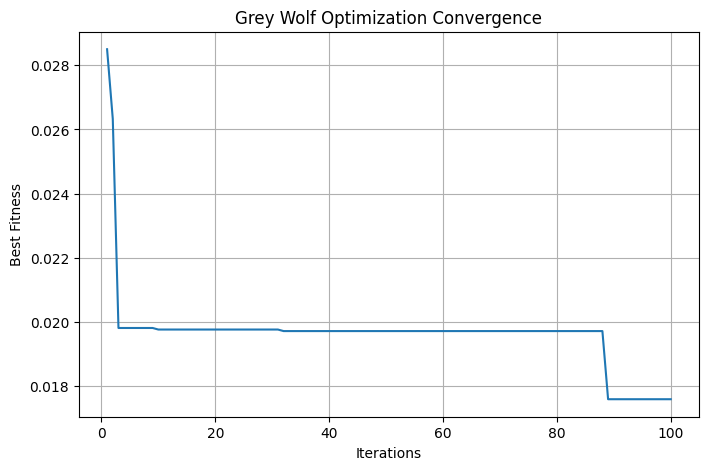

In [1]:

# GREY WOLF OPTIMIZATION FOR MACHINE LEARNING
# Feature Selection using KNN Classifier

import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report

# 1. Load Dataset
data = load_breast_cancer()
X = data.data
y = data.target
features = data.feature_names

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 2. Fitness Function
def fitness(wolf):
    selected = wolf.astype(bool)

    if np.sum(selected) == 0:
        return 1.0

    model = make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=5)
    )

    cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

    scores = cross_val_score(
        model, X_train[:, selected], y_train,
        cv=cv, scoring='accuracy'
    )

    return 1 - np.mean(scores)

# 3. Binary Conversion
def sigmoid(x):
    return 1 / (1 + np.exp(-np.clip(x, -50, 50)))

def binary_conversion(position):
    return (np.random.rand(len(position)) < sigmoid(position)).astype(int)

# 4. Grey Wolf Optimization
def GWO(N, T, D):
    population = np.random.uniform(-6, 6, (N, D))

    alpha_score = beta_score = delta_score = float('inf')
    alpha = beta = delta = None
    best_mask = None
    convergence = []

    for t in range(T):
        a = 2 - 2 * t / T

        for i in range(N):
            wolf = binary_conversion(population[i])
            score = fitness(wolf)

            if score < alpha_score:
                delta_score, delta = beta_score, beta
                beta_score, beta = alpha_score, alpha
                alpha_score, alpha = score, population[i].copy()
                best_mask = wolf.copy()

            elif score < beta_score:
                delta_score, delta = beta_score, beta
                beta_score, beta = score, population[i].copy()

            elif score < delta_score:
                delta_score, delta = score, population[i].copy()

        for i in range(N):
            positions = []

            for leader in [alpha, beta, delta]:
                A = 2 * a * np.random.rand(D) - a
                C = 2 * np.random.rand(D)
                distance = abs(C * leader - population[i])
                positions.append(leader - A * distance)

            population[i] = np.clip(np.mean(positions, axis=0), -6, 6)

        convergence.append(alpha_score)
        print(f"Iteration {t+1}/{T} - Best Fitness: {alpha_score:.5f}")

    return best_mask, alpha_score, convergence

# 5. Run GWO
print("Starting Grey Wolf Optimization...\n")

best_features, best_fitness, convergence = GWO(
    N=30,
    T=100,
    D=X_train.shape[1]
)

# 6. Display Selected Features
selected = best_features.astype(bool)

print("\nSelected Features:")
for feature in features[selected]:
    print(feature)

print("\nTotal Selected Features:", np.sum(selected))
print("Original Features:", X.shape[1])
print("Best Fitness:", best_fitness)

# 7. Train KNN Model
model = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=5)
)

model.fit(X_train[:, selected], y_train)

predictions = model.predict(X_test[:, selected])

# 8. Evaluate Model
accuracy = accuracy_score(y_test, predictions)

print("\n--- MODEL PERFORMANCE ---")
print("Accuracy:", round(accuracy * 100, 2), "%")
print("\nClassification Report:")
print(classification_report(y_test, predictions))

# 9. Convergence Graph
plt.figure(figsize=(8, 5))
plt.plot(range(1, 101), convergence)
plt.xlabel("Iterations")
plt.ylabel("Best Fitness")
plt.title("Grey Wolf Optimization Convergence")
plt.grid(True)
plt.show()
